In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import os

from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D, Input
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [4]:
TRAIN_PATH = "D:\\Artificial Intelligence\\Deep Learning\Data\\Icream_pizza\\Train"
VAL_PATH = "D:\\Artificial Intelligence\\Deep Learning\\Data\\Icream_pizza\\valid"
TEST_PATH = "D:\\Artificial Intelligence\\Deep Learning\\Data\\Icream_pizza\\Test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 30
MODEL_PATH = "resnet.weights.h5"

<>:1: SyntaxWarning: invalid escape sequence '\D'
<>:1: SyntaxWarning: invalid escape sequence '\D'
C:\Users\HASEEB\AppData\Local\Temp\ipykernel_3776\1572307684.py:1: SyntaxWarning: invalid escape sequence '\D'
  TRAIN_PATH = "D:\\Artificial Intelligence\\Deep Learning\Data\\Icream_pizza\\Train"


In [5]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = test_datagen.flow_from_directory(
    VAL_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 718 images belonging to 2 classes.
Found 208 images belonging to 2 classes.
Found 106 images belonging to 2 classes.


Classes: ['icecream', 'pizza']


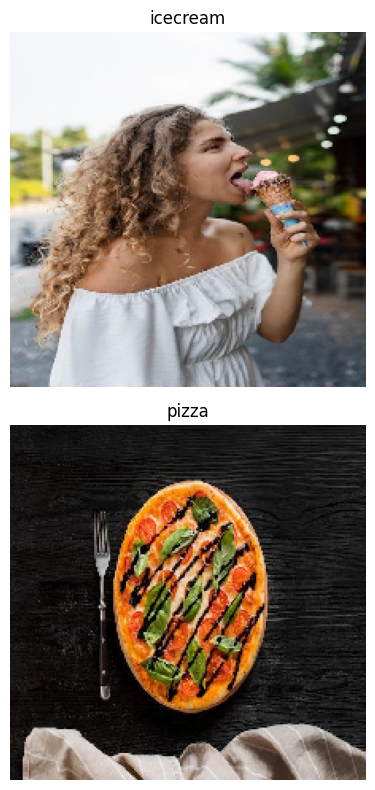

In [6]:
class_names = list(train_generator.class_indices.keys())
num_classes = len(class_names)

print("Classes:", class_names)

plt.figure(figsize=(15,8))

for i, cls in enumerate(class_names):
    folder = os.path.join(TRAIN_PATH, cls)
    img_name = os.listdir(folder)[0]
    img_path = os.path.join(folder, img_name)

    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img = tf.keras.utils.img_to_array(img)/255.0

    plt.subplot(2, (num_classes+1)//2, i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False


inputs = Input(shape=(224,224,3))

x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)

x = Dense(128, activation='relu')(x)
x = Dropout(0.2)(x)

outputs = Dense(num_classes, activation='softmax')(x)

model = Model(inputs, outputs)

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 495s 5us/step


In [8]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# CALLBACKS
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    MODEL_PATH,
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

In [10]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

val_generator = test_datagen.flow_from_directory(
    VAL_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 718 images belonging to 2 classes.
Found 208 images belonging to 2 classes.
Found 106 images belonging to 2 classes.


Classes: ['icecream', 'pizza']


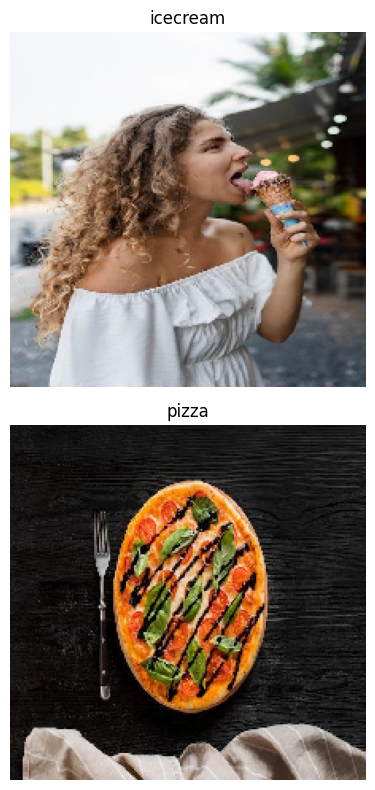

In [11]:
class_names = list(train_generator.class_indices.keys())
num_classes = len(class_names)

print("Classes:", class_names)


plt.figure(figsize=(15,8))

for i, cls in enumerate(class_names):
    folder = os.path.join(TRAIN_PATH, cls)
    img_name = os.listdir(folder)[0]
    img_path = os.path.join(folder, img_name)

    img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
    img = tf.keras.utils.img_to_array(img)/255.0

    plt.subplot(2, (num_classes+1)//2, i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

base_model.trainable = False

inputs = Input(shape=(224,224,3))

x = base_model(inputs, training=False)
x = GlobalAveragePooling2D()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.3)(x)

x = Dense(128, activation='relu')(x)
x = Dropout(0.2)(x)

outputs = Dense(num_classes, activation='softmax')(x)

model = Model(inputs, outputs)

In [13]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# CALLBACKS
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    MODEL_PATH,
    monitor='val_accuracy',
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

In [14]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/30
14/23 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step - accuracy: 0.4670 - loss: 0.8924

KeyboardInterrupt: 

In [ ]:
model.load_weights(MODEL_PATH)

# TEST ACCURACY
test_loss, test_acc = model.evaluate(test_generator)

print("Test Accuracy :", round(test_acc*100,2), "%")
print("Test Loss     :", round(test_loss,4))

12/12 ━━━━━━━━━━━━━━━━━━━━ 17s 2s/step - accuracy: 0.1027 - loss: 3.3075
Test Accuracy : 12.53 %
Test Loss     : 3.1912


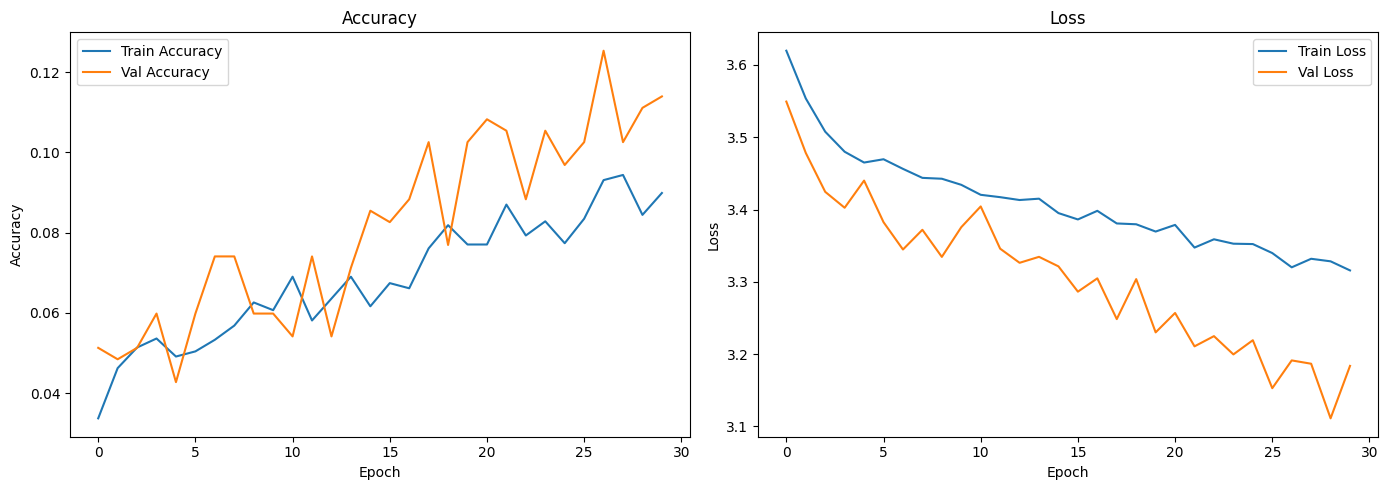

In [ ]:
plt.figure(figsize=(14,5))

plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title("Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

12/12 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step


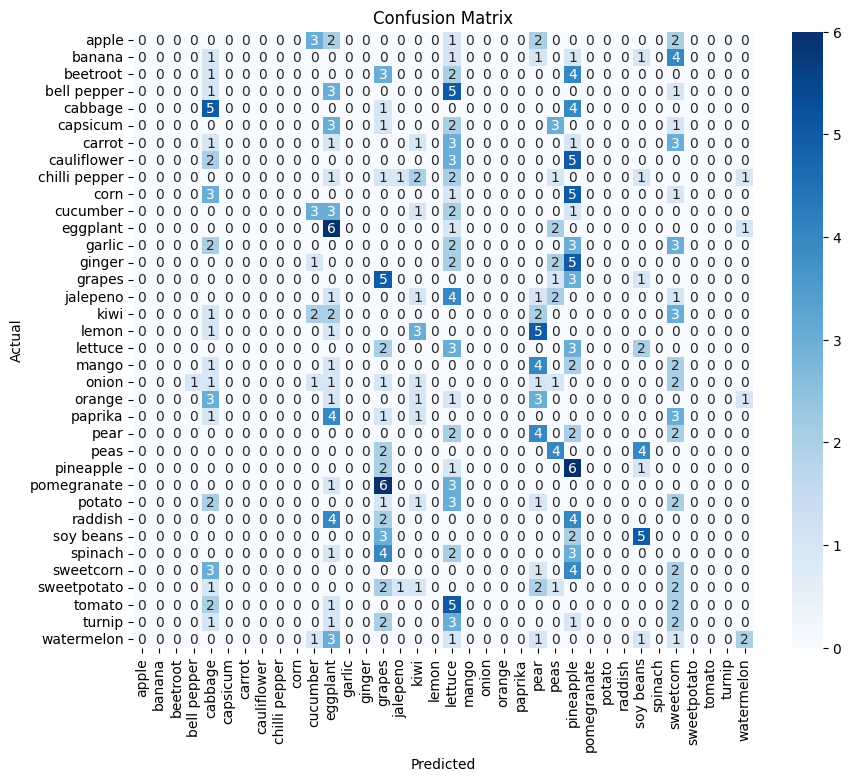

In [ ]:
test_generator.reset()

pred_probs = model.predict(test_generator)
y_pred = np.argmax(pred_probs, axis=1)
y_true = test_generator.classes

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
print("\nClassification Report:\n")

report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print(report)


Classification Report:

               precision    recall  f1-score   support

        apple       0.00      0.00      0.00        10
       banana       0.00      0.00      0.00         9
     beetroot       0.00      0.00      0.00        10
  bell pepper       0.00      0.00      0.00        10
      cabbage       0.15      0.50      0.23        10
     capsicum       0.00      0.00      0.00        10
       carrot       0.00      0.00      0.00        10
  cauliflower       0.00      0.00      0.00        10
chilli pepper       0.00      0.00      0.00        10
         corn       0.00      0.00      0.00        10
     cucumber       0.27      0.30      0.29        10
     eggplant       0.15      0.60      0.24        10
       garlic       0.00      0.00      0.00        10
       ginger       0.00      0.00      0.00        10
       grapes       0.13      0.50      0.20        10
     jalepeno       0.00      0.00      0.00        10
         kiwi       0.00      0.00     

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
model.save("resnet_model.h5")

NameError: name 'model' is not defined

In [ ]:
img_path = "sample.jpg"

img = tf.keras.utils.load_img(img_path, target_size=IMG_SIZE)
img = tf.keras.utils.img_to_array(img)/255.0
img = np.expand_dims(img, axis=0)

pred = model.predict(img)

pred_class = class_names[np.argmax(pred)]
confidence = np.max(pred)

print("Predicted Class :", pred_class)
print("Confidence      :", round(confidence*100,2), "%")

FileNotFoundError: [Errno 2] No such file or directory: 'sample.jpg'